<a href="https://colab.research.google.com/github/siriscent7/CS228_project/blob/main/two_tier_face_verification_xqlfw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Two-tier face verification on XQLFW
Adapted from your `two_tier_face_verification_final.ipynb`.

**Question:** Does selective FP32 fallback recover INT8 verification errors on cross-quality faces, at a useful compute cost?
XQLFW is an evaluation benchmark, not a training improvement. Accuracy may decrease relative to LFW.
Compare FP32, INT8-only, margin fallback and a random fallback control **on the same held-out pairs**.

## Run in Google Colab
1. Select **CPU** runtime. Upload this notebook to Colab.
2. Put your existing `w600k_r50.onnx` and `w600k_r50_int8.onnx` in `/content/drive/MyDrive/CS228`.
   They are not in the uploaded project ZIP. Generate INT8 with your original notebook if needed;
   keep exactly the same weights for this first transfer experiment.
3. Run all cells. The notebook downloads official aligned XQLFW images and pairs automatically.
4. Leave `SMOKE_PAIRS_PER_CLASS_PER_FOLD = None` for the full 6,000-pair result.
   Set it to `10` for a 200-pair smoke run first. Smoke results are not benchmark results.
5. Review `summary_mean.csv`, `paired_changes.csv` and `tradeoffs.png` under `results_xqlfw/official_10fold/full`.

**Protocol:** Preserve the supplied 10 folds; calibrate thresholds and margin widths on nine folds,
then test on the remaining fold. Accuracy here is measured at a **1% calibration FAR target**,
not the accuracy-maximizing threshold normally reported in benchmark leaderboards.
Report measured test FAR alongside TAR. Actual escalation can differ from the calibration budget.

**Important limitation:** XQLFW is derived from LFW. Your old INT8 model was calibrated on LFW,
so image/identity overlap is possible. This is a frozen-model transfer experiment, not a guaranteed
unseen-identity test. The original notebook also uses split-0 calibration images for all ten random splits;
those images can appear in later test splits (and repeated images can cross pair splits).
For a stronger final result, calibrate quantization using a separate, disjoint dataset and rerun both benchmarks.
Do not quantize or choose an INT8 variant using all XQLFW test images.

Sources: [XQLFW paper](https://arxiv.org/abs/2108.10290),
[official downloads](https://martlgap.github.io/xqlfw/pages/download.html),
[official evaluation code](https://github.com/Martlgap/xqlfw).


In [1]:
try:
    from google.colab import drive
except ImportError:
    print("Outside Colab: set PROJECT_DIR below to your local model folder.")
else:
    drive.mount('/content/drive')
%pip install -q onnxruntime pillow numpy pandas matplotlib scikit-learn


Mounted at /content/drive


In [2]:
import io, json, pickle, hashlib, platform, time, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score
import onnxruntime as ort

PROJECT_DIR = Path('/content/drive/MyDrive/CS228')
FP32_PATH = PROJECT_DIR / 'w600k_r50.onnx'
INT8_PATH = PROJECT_DIR / 'w600k_r50_int8.onnx'
DATASET = 'xqlfw'                 # optional: 'lfw' to reevaluate lfw.bin with the same settings
PROTOCOL = 'official_10fold'      # optional: 'random_50_50' for the original split strategy
# For LFW official_10fold, lfw.bin MUST retain the original official pair ordering.
SMOKE_PAIRS_PER_CLASS_PER_FOLD = None  # 10 -> 200 pairs; None -> all 6000
FAR_TARGET = 0.01
BUDGETS = (0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.20)
SEED = 0
THREADS = 2                     # use the same value and machine for both datasets
BATCH_SIZE = 32
MODEL_PROVENANCE = 'Frozen INT8 from original LFW experiment; possible LFW/XQLFW overlap.'
DATA_DIR = PROJECT_DIR / 'data_xqlfw'
RUN_NAME = 'full' if SMOKE_PAIRS_PER_CLASS_PER_FOLD is None else f'smoke_{SMOKE_PAIRS_PER_CLASS_PER_FOLD}'
OUT_DIR = PROJECT_DIR / f'results_{DATASET}' / PROTOCOL / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert DATASET in ('xqlfw', 'lfw')
assert PROTOCOL in ('official_10fold', 'random_50_50')
for p in (FP32_PATH, INT8_PATH):
    if not p.is_file():
        raise FileNotFoundError(f'Missing {p}. Copy the existing model from your original experiment.')
print('Dataset:', DATASET, '| Protocol:', PROTOCOL, '| ORT:', ort.__version__)
print('Model provenance:', MODEL_PROVENANCE)


Dataset: xqlfw | Protocol: official_10fold | ORT: 1.32.0
Model provenance: Frozen INT8 from original LFW experiment; possible LFW/XQLFW overlap.


In [3]:
# Official release files; download once. A partial download never becomes the final file.
BASE_URL = 'https://github.com/Martlgap/xqlfw/releases/download/1.0/'
def download_once(url, destination):
    destination = Path(destination)
    if destination.is_file():
        return
    destination.parent.mkdir(parents=True, exist_ok=True)
    tmp = destination.with_suffix(destination.suffix + '.part')
    try:
        print('Downloading', destination.name, flush=True)
        with urllib.request.urlopen(url, timeout=120) as response, tmp.open('wb') as out:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                out.write(chunk)
        tmp.replace(destination)
    finally:
        if tmp.exists():
            tmp.unlink()

if DATASET == 'xqlfw':
    ZIP_PATH = DATA_DIR / 'xqlfw_aligned_112.zip'
    PAIRS_PATH = DATA_DIR / 'xqlfw_pairs.txt'
    download_once(BASE_URL + ZIP_PATH.name, ZIP_PATH)
    download_once(BASE_URL + PAIRS_PATH.name, PAIRS_PATH)
    print('Official XQLFW files ready.')


Official XQLFW files ready.


In [4]:
# Read the official LFW-style pairs file without changing its fold order.
def parse_pairs(text):
    lines = [line.split() for line in text.splitlines() if line.strip()]
    if not lines or lines[0] != ['10', '300']:
        raise ValueError('Expected the official 10-fold, 300-pairs-per-class XQLFW protocol.')
    rows = lines[1:]
    if len(rows) != 6000:
        raise ValueError(f'Expected 6000 pairs; found {len(rows)}.')
    paths_a, paths_b, labels, folds = [], [], [], []
    def filename(name, idx):
        if '/' in name or '\\' in name or int(idx) < 1:
            raise ValueError('Invalid identity or image index.')
        return f'{name}/{name}_{int(idx):04d}.jpg'
    for i, row in enumerate(rows):
        expected_same = i % 600 < 300
        if len(row) != (3 if expected_same else 4):
            raise ValueError(f'Invalid pair/fold ordering at pair {i}.')
        if expected_same:
            a, b = filename(row[0], row[1]), filename(row[0], row[2])
        else:
            a, b = filename(row[0], row[1]), filename(row[2], row[3])
        paths_a.append(a); paths_b.append(b)
        labels.append(int(expected_same)); folds.append(i // 600)
    return paths_a, paths_b, np.array(labels), np.array(folds)

def select_pairs(labels, folds, per_class=None, seed=0):
    if per_class is None:
        return np.arange(len(labels))
    if not isinstance(per_class, int) or not 1 <= per_class <= 300:
        raise ValueError('Smoke sample size must be an integer in [1, 300].')
    rng = np.random.default_rng(seed)
    return np.sort(np.concatenate([
        rng.choice(np.flatnonzero((folds == fold) & (labels == y)), per_class, replace=False)
        for fold in range(10) for y in (0, 1)
    ]))

def decode_image(blob):
    with Image.open(io.BytesIO(blob)) as image:
        image = np.asarray(image.convert('RGB'))
    if image.shape != (112, 112, 3):
        raise ValueError(f'Expected aligned 112x112 RGB image; got {image.shape}.')
    return image

def load_xqlfw(archive, pairs_file, per_class=None):
    a, b, y, folds = parse_pairs(Path(pairs_file).read_text())
    selected = select_pairs(y, folds, per_class, SEED)
    a = [a[i] for i in selected]; b = [b[i] for i in selected]
    names = sorted(set(a + b))
    with zipfile.ZipFile(archive) as z:
        # Handles an optional top-level directory in the official archive.
        members = {}
        for member in z.namelist():
            parts = Path(member).parts
            if len(parts) >= 2 and member.lower().endswith('.jpg'):
                key = '/'.join(parts[-2:])
                if key in members:
                    raise ValueError(f'Ambiguous archive image: {key}')
                members[key] = member
        missing = set(names) - members.keys()
        if missing:
            raise FileNotFoundError(f'{len(missing)} images missing, e.g. {sorted(missing)[:3]}')
        images = np.stack([decode_image(z.read(members[name])) for name in names])
    lookup = {name: i for i, name in enumerate(names)}
    ia = np.array([lookup[name] for name in a]); ib = np.array([lookup[name] for name in b])
    return images, ia, ib, y[selected], folds[selected], selected

def load_lfw(path, per_class=None):
    # Only load a trusted InsightFace .bin file: pickle can execute code.
    with Path(path).open('rb') as f:
        bins, labels = pickle.load(f, encoding='bytes')
    labels = np.asarray(labels, dtype=int)
    if len(labels) != 6000 or len(bins) != 12000:
        raise ValueError('Expected the full ordered LFW .bin: 6000 pairs / 12000 images.')
    folds = np.arange(6000) // 600
    expected = (np.arange(6000) % 600 < 300).astype(int)
    if not np.array_equal(labels, expected):
        raise ValueError('LFW .bin does not match expected fold/class ordering.')
    selected = select_pairs(labels, folds, per_class, SEED)
    images, lookup, sides = [], {}, []
    for side in (0, 1):
        ids = []
        for pair in selected:
            blob = bins[2 * pair + side]
            digest = hashlib.sha256(blob).hexdigest()
            if digest not in lookup:
                lookup[digest] = len(images); images.append(decode_image(blob))
            ids.append(lookup[digest])
        sides.append(np.array(ids))
    return np.stack(images), *sides, labels[selected], folds[selected], selected

if DATASET == 'xqlfw':
    images, ia, ib, labels, folds, pair_ids = load_xqlfw(ZIP_PATH, PAIRS_PATH, SMOKE_PAIRS_PER_CLASS_PER_FOLD)
else:
    images, ia, ib, labels, folds, pair_ids = load_lfw(PROJECT_DIR / 'lfw.bin', SMOKE_PAIRS_PER_CLASS_PER_FOLD)
print(f'{len(labels)} pairs, {labels.sum()} genuine, {(labels == 0).sum()} impostor; {len(images)} unique images')
if SMOKE_PAIRS_PER_CLASS_PER_FOLD is not None:
    print('SMOKE RUN ONLY: too few impostors for reliable 1% FAR estimates.')


6000 pairs, 3000 genuine, 3000 impostor; 7263 unique images


In [5]:
# ---------------- embedder (ONNX Runtime, CPU) ----------------
class OrtEmbedder:
    def __init__(self, path, threads=0):
        opts = ort.SessionOptions()
        if threads: opts.intra_op_num_threads = threads
        self.sess = ort.InferenceSession(str(path), opts, providers=["CPUExecutionProvider"])
        inp = self.sess.get_inputs()[0]
        self.name = inp.name
        self.fixed = inp.shape[0] if isinstance(inp.shape[0], int) else None   # fixed batch size, if any

    @staticmethod
    def prep(images_u8):                              # RGB uint8 NHWC -> float NCHW in [-1, 1]
        x = (images_u8.astype(np.float32) - 127.5) / 127.5
        return np.ascontiguousarray(x.transpose(0, 3, 1, 2))

    def embed(self, images_u8, batch_size=32):
        bs = self.fixed or batch_size
        out = []
        for i in range(0, len(images_u8), bs):
            chunk = images_u8[i:i + bs]; n = len(chunk)
            if self.fixed and n < bs:                 # pad the last batch for fixed-batch models
                chunk = np.concatenate([chunk, np.repeat(chunk[-1:], bs - n, axis=0)])
            out.append(self.sess.run(None, {self.name: self.prep(chunk)})[0][:n])
        e = np.concatenate(out)
        return e / np.linalg.norm(e, axis=1, keepdims=True)


fp32 = OrtEmbedder(FP32_PATH, THREADS)
int8 = OrtEmbedder(INT8_PATH, THREADS)
print('FP32 / INT8 MB:', round(FP32_PATH.stat().st_size / 1e6, 2), round(INT8_PATH.stat().st_size / 1e6, 2))


FP32 / INT8 MB: 174.38 43.99


In [6]:
# Hash model bytes AND selected image pixels/order. Never reuse LFW scores for XQLFW.
def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def data_hash(images, ia, ib, labels, folds):
    h = hashlib.sha256()
    for arr in (images, ia, ib, labels, folds):
        arr = np.ascontiguousarray(arr)
        h.update(str((arr.dtype.str, arr.shape)).encode())
        h.update(memoryview(arr).cast('B'))
    return h.hexdigest()

signature = json.dumps(dict(dataset=DATASET, data_sha256=data_hash(images, ia, ib, labels, folds),
                           fp32_sha256=file_hash(FP32_PATH), int8_sha256=file_hash(INT8_PATH),
                           preprocessing='RGB_(x-127.5)/127.5_NCHW_L2_v1',
                           ort=ort.__version__, threads=THREADS, batch_size=BATCH_SIZE), sort_keys=True)
CACHE_PATH = OUT_DIR / 'scores.npz'
use_cache = False
if CACHE_PATH.exists():
    with np.load(CACHE_PATH, allow_pickle=False) as cache:
        if 'signature' in cache and str(cache['signature'].item()) == signature:
            s_fp32, s_int8 = cache['s_fp32'].copy(), cache['s_int8'].copy()
            use_cache = True
if not use_cache:
    def score_model(model):
        started = time.perf_counter()
        embeddings = []
        for start in range(0, len(images), 256):
            embeddings.append(model.embed(images[start:start+256], BATCH_SIZE))
            print(f'{min(start+256, len(images))}/{len(images)} images', end='; ', flush=True)
        embeddings = np.concatenate(embeddings)
        scores = np.sum(embeddings[ia] * embeddings[ib], axis=1)
        print(f'finished in {time.perf_counter()-started:.1f}s')
        return scores
    print('FP32:'); s_fp32 = score_model(fp32)
    print('INT8:'); s_int8 = score_model(int8)
    np.savez(CACHE_PATH, signature=signature, s_fp32=s_fp32, s_int8=s_int8,
             labels=labels, folds=folds, pair_ids=pair_ids)
else:
    print('Loaded verified score cache.')
s_fp32 = np.asarray(s_fp32, dtype=np.float64)
s_int8 = np.asarray(s_int8, dtype=np.float64)
assert s_fp32.shape == labels.shape == s_int8.shape
assert np.isfinite(s_fp32).all() and np.isfinite(s_int8).all()
print('AUC:', {'FP32': roc_auc_score(labels, s_fp32), 'INT8': roc_auc_score(labels, s_int8)})


FP32:
256/7263 images; 512/7263 images; 768/7263 images; 1024/7263 images; 1280/7263 images; 1536/7263 images; 1792/7263 images; 2048/7263 images; 2304/7263 images; 2560/7263 images; 2816/7263 images; 3072/7263 images; 3328/7263 images; 3584/7263 images; 3840/7263 images; 4096/7263 images; 4352/7263 images; 4608/7263 images; 4864/7263 images; 5120/7263 images; 5376/7263 images; 5632/7263 images; 5888/7263 images; 6144/7263 images; 6400/7263 images; 6656/7263 images; 6912/7263 images; 7168/7263 images; 7263/7263 images; finished in 1095.1s
INT8:
256/7263 images; 512/7263 images; 768/7263 images; 1024/7263 images; 1280/7263 images; 1536/7263 images; 1792/7263 images; 2048/7263 images; 2304/7263 images; 2560/7263 images; 2816/7263 images; 3072/7263 images; 3328/7263 images; 3584/7263 images; 3840/7263 images; 4096/7263 images; 4352/7263 images; 4608/7263 images; 4864/7263 images; 5120/7263 images; 5376/7263 images; 5632/7263 images; 5888/7263 images; 6144/7263 images; 6400/7263 images; 66

In [7]:
# Re-measure on this CPU; do not reuse old Colab latency metadata.
def bench_pair(model, warmup=3, reps=15):
    for _ in range(warmup):
        model.embed(images[:1], 1); model.embed(images[1:2], 1)
    durations = []
    for i in range(reps):
        pair = i % len(ia)
        a, b = images[ia[pair]:ia[pair]+1], images[ib[pair]:ib[pair]+1]
        start = time.perf_counter()
        model.embed(a, 1); model.embed(b, 1)
        durations.append(1000 * (time.perf_counter()-start))
    return float(np.median(durations))
c1, c2 = bench_pair(int8), bench_pair(fp32)
print(f'INT8: {c1:.2f} ms/pair; FP32: {c2:.2f} ms/pair')
print(f'Estimated break-even escalation: {1-c1/c2:.1%}')
print('Two-tier latency is estimated as c1 + escalation*c2; excludes detection/alignment and routing overhead.')


INT8: 220.72 ms/pair; FP32: 279.45 ms/pair
Estimated break-even escalation: 21.0%
Two-tier latency is estimated as c1 + escalation*c2; excludes detection/alignment and routing overhead.


In [8]:
def evaluation_splits(labels, folds, protocol, seed=0):
    if protocol == 'official_10fold':
        return [(np.flatnonzero(folds != fold), np.flatnonzero(folds == fold)) for fold in range(10)]
    rng = np.random.RandomState(seed)
    splits = []
    for _ in range(10):
        cal, test = [], []
        for y in (0, 1):
            idx = rng.permutation(np.flatnonzero(labels == y)); half = len(idx)//2
            cal.extend(idx[:half]); test.extend(idx[half:])
        splits.append((np.sort(cal), np.sort(test)))
    return splits

def tau_at_far(negative_scores, far):
    # Decision is score >= threshold. Move ABOVE the boundary to avoid the original
    # off-by-one/tie issue; empirical calibration FAR will be <= the requested target.
    neg = np.sort(np.asarray(negative_scores, dtype=np.float64))
    if not len(neg) or not 0 <= far < 1 or not np.isfinite(neg).all():
        raise ValueError('Need finite impostor scores and 0 <= FAR < 1.')
    allowed = int(np.floor(far * len(neg)))
    return np.nextafter(neg[len(neg)-allowed-1], np.inf)

def delta_for_budget(scores, tau, budget):
    if not 0 <= budget <= 1:
        raise ValueError('Budget must lie in [0, 1].')
    return float(np.quantile(np.abs(scores-tau), budget)) if budget else 0.0

def two_tier(s8, s32, t8, t32, delta):
    escalate = np.abs(s8-t8) < delta
    return np.where(escalate, s32 >= t32, s8 >= t8), escalate

splits = evaluation_splits(labels, folds, PROTOCOL, SEED)
rows, threshold_rows = [], []
for split, (cal, test) in enumerate(splits):
    assert not np.intersect1d(cal, test).size
    t32 = tau_at_far(s_fp32[cal][labels[cal] == 0], FAR_TARGET)
    t8 = tau_at_far(s_int8[cal][labels[cal] == 0], FAR_TARGET)
    ref, baseline = s_fp32[test] >= t32, s_int8[test] >= t8
    truth = labels[test].astype(bool)
    n = len(test)
    threshold_rows.append(dict(split=split, tau_fp32=t32, tau_int8=t8,
        calibration_FAR_fp32=np.mean(s_fp32[cal][labels[cal] == 0] >= t32),
        calibration_FAR_int8=np.mean(s_int8[cal][labels[cal] == 0] >= t8)))
    def add(system, prediction, escalation, budget=np.nan):
        corrected = np.sum((baseline != truth) & (prediction == truth))
        introduced = np.sum((baseline == truth) & (prediction != truth))
        rate = float(np.mean(escalation))
        latency = c2 if system == 'FP32' else c1 + rate*c2
        rows.append(dict(split=split, system=system, budget=budget, n_test=n,
            accuracy=float(np.mean(prediction == truth)), TAR=float(prediction[truth].mean()),
            FAR=float(prediction[~truth].mean()), agreement_FP32=float(np.mean(prediction == ref)),
            escalation=rate, estimated_latency_ms=latency, estimated_speedup=c2/latency,
            corrected_vs_INT8=int(corrected), introduced_vs_INT8=int(introduced),
            accuracy_gain_pp=100*float(corrected-introduced)/n))
    add('FP32', ref, np.zeros(n, bool))  # no fallback stage for FP32-only
    add('INT8', baseline, np.zeros(n, bool))
    for budget in BUDGETS:
        delta = delta_for_budget(s_int8[cal], t8, budget)
        prediction, escalated = two_tier(s_int8[test], s_fp32[test], t8, t32, delta)
        add(f'Margin b={budget:g}', prediction, escalated, budget)
        # Exact matching number of random escalations on this held-out fold.
        rng = np.random.default_rng(SEED + 1000*split + int(budget*10000))
        random_mask = np.zeros(n, bool)
        random_mask[rng.choice(n, size=int(escalated.sum()), replace=False)] = True
        add(f'Random b={budget:g}', np.where(random_mask, ref, baseline), random_mask, budget)

df = pd.DataFrame(rows)
metrics = ['accuracy', 'TAR', 'FAR', 'agreement_FP32', 'escalation', 'estimated_latency_ms', 'estimated_speedup', 'accuracy_gain_pp']
mean = df.groupby('system', sort=False)[metrics].mean()
std = df.groupby('system', sort=False)[metrics].std()
print('Means across folds/splits (accuracy_gain_pp is percentage points relative to INT8):')
display(mean.round(5))
print('Fold/split standard deviations are descriptive; they are not confidence intervals.')


Means across folds/splits (accuracy_gain_pp is percentage points relative to INT8):


,accuracy,TAR,FAR,agreement_FP32,escalation,estimated_latency_ms,estimated_speedup,accuracy_gain_pp
system,,,,,,,,
FP32,0.89250,0.79567,0.01067,1.00000,0.00000,279.44871,1.00000,0.41667
INT8,0.88833,0.78767,0.01100,0.98250,0.00000,220.72244,1.26606,0.00000
Margin b=0.005,0.88883,0.78867,0.01100,0.98467,0.00533,222.21284,1.25759,0.05000
Random b=0.005,0.88833,0.78767,0.01100,0.98250,0.00533,222.21284,1.25759,0.00000
Margin b=0.01,0.88900,0.78800,0.01000,0.98717,0.01033,223.61008,1.24976,0.06667
Random b=0.01,0.88800,0.78700,0.01100,0.98283,0.01033,223.61008,1.24976,-0.03333
Margin b=0.02,0.89050,0.79100,0.01000,0.99100,0.02033,226.40457,1.23437,0.21667
Random b=0.02,0.88850,0.78800,0.01100,0.98267,0.02033,226.40457,1.23437,0.01667
Margin b=0.03,0.89033,0.79067,0.01000,0.99250,0.02950,228.96618,1.22060,0.20000


Fold/split standard deviations are descriptive; they are not confidence intervals.


Corrections and introduced errors versus INT8:


,n_test,corrected_vs_INT8,introduced_vs_INT8,net_corrected,accuracy_gain_pp
system,,,,,
FP32,6000,65,40,25,0.416667
INT8,6000,0,0,0,0.000000
Margin b=0.005,6000,8,5,3,0.050000
Random b=0.005,6000,0,0,0,0.000000
Margin b=0.01,6000,16,12,4,0.066667
Random b=0.01,6000,0,2,-2,-0.033333
Margin b=0.02,6000,32,19,13,0.216667
Random b=0.02,6000,1,0,1,0.016667
Margin b=0.03,6000,36,24,12,0.200000


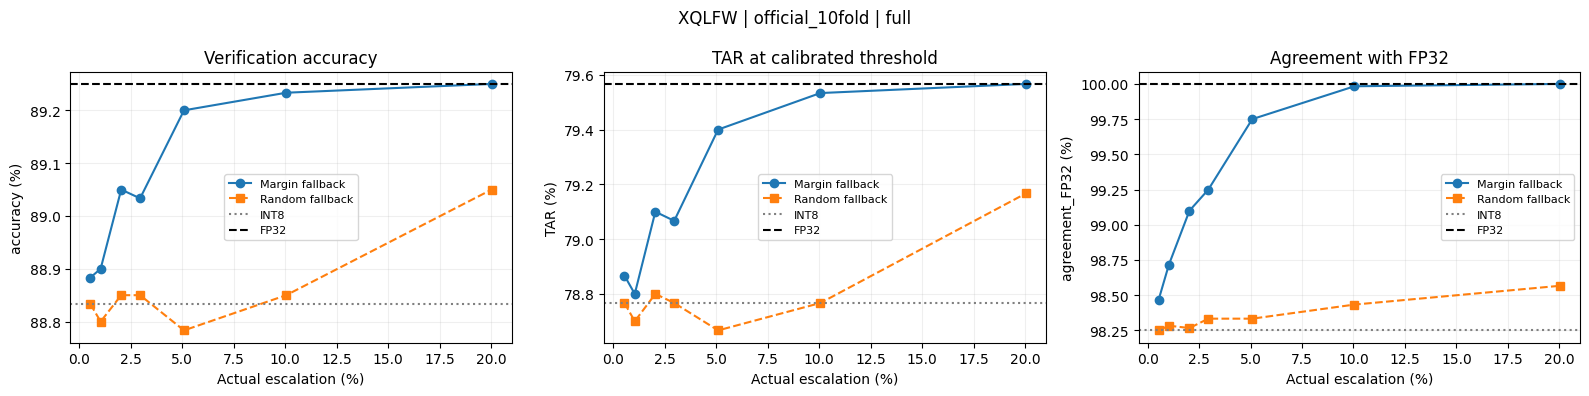

Saved: /content/drive/MyDrive/CS228/results_xqlfw/official_10fold/full


In [9]:
mean.to_csv(OUT_DIR / 'summary_mean.csv')
std.to_csv(OUT_DIR / 'summary_std.csv')
df.to_csv(OUT_DIR / 'all_splits.csv', index=False)
pd.DataFrame(threshold_rows).to_csv(OUT_DIR / 'thresholds.csv', index=False)
paired = df.groupby('system', sort=False)[['n_test', 'corrected_vs_INT8', 'introduced_vs_INT8']].sum()
paired['net_corrected'] = paired.corrected_vs_INT8 - paired.introduced_vs_INT8
paired['accuracy_gain_pp'] = 100*paired.net_corrected/paired.n_test
paired.to_csv(OUT_DIR / 'paired_changes.csv')
print('Corrections and introduced errors versus INT8:')
display(paired)
if PROTOCOL == 'random_50_50':
    print('These summed counts include repeated pair appearances across test splits.')
metadata = dict(dataset=DATASET, protocol=PROTOCOL, smoke=SMOKE_PAIRS_PER_CLASS_PER_FOLD,
    n_pairs=len(labels), n_unique_images=len(images), far_target=FAR_TARGET, budgets=BUDGETS,
    seed=SEED, model_provenance=MODEL_PROVENANCE, signature=json.loads(signature),
    c1_ms=c1, c2_ms=c2, latency_type='estimated c1 + escalation*c2; no detection/alignment',
    cpu=platform.processor(), platform=platform.platform(), threads=THREADS,
    auc_fp32=float(roc_auc_score(labels, s_fp32)), auc_int8=float(roc_auc_score(labels, s_int8)),
    accuracy_definition='held-out accuracy at calibration FAR target; not max-accuracy threshold',
    warning='LFW/XQLFW identity overlap possible; original INT8 calibration uses LFW images')
(OUT_DIR / 'meta.json').write_text(json.dumps(metadata, indent=2))

margin = mean.loc[[x for x in mean.index if x.startswith('Margin')]]
random = mean.loc[[x for x in mean.index if x.startswith('Random')]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes, ['accuracy', 'TAR', 'agreement_FP32'],
                           ['Verification accuracy', 'TAR at calibrated threshold', 'Agreement with FP32']):
    ax.plot(100*margin.escalation, 100*margin[metric], 'o-', label='Margin fallback')
    ax.plot(100*random.escalation, 100*random[metric], 's--', label='Random fallback')
    ax.axhline(100*mean.loc['INT8', metric], color='gray', ls=':', label='INT8')
    ax.axhline(100*mean.loc['FP32', metric], color='black', ls='--', label='FP32')
    ax.set(xlabel='Actual escalation (%)', ylabel=metric + ' (%)', title=title)
    ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.suptitle(f'{DATASET.upper()} | {PROTOCOL} | {RUN_NAME}')
fig.tight_layout(); fig.savefig(OUT_DIR / 'tradeoffs.png', dpi=160); plt.show()
print('Saved:', OUT_DIR)


## Interpret the experiment
- **Benefit over INT8:** positive `accuracy_gain_pp` means the fallback corrected more errors than it introduced.
  Check TAR and measured FAR too; a higher TAR with a higher FAR is not a free improvement.
- **Compute tradeoff:** seek high agreement/accuracy at low actual escalation. `estimated_speedup > 1`
  indicates an estimated advantage over FP32-only on this CPU. It is not measured end-to-end latency.
- **Quality matters:** lower XQLFW accuracy than LFW is expected to be possible. The useful result is
  whether selective fallback recovers INT8 errors better than random fallback at the same cost.
  FP32 cannot recover visual information lost to degradation; both models may make the same errors.
- **Fair comparison:** rerun with `DATASET='lfw'`, using the same protocol, model files, CPU and thread count.
  Do not directly equate this default nine-fold calibration protocol with the old random 50/50 results.
  The FAR boundary handling has also been corrected, so reevaluate LFW rather than copying old numbers.
- **Avoid tuning on test results:** the budget sweep describes a tradeoff. If selecting one deployment
  budget, choose it on separate validation data, or use nested validation before reporting its final test result.
- **Strong conclusion template:** “On XQLFW, two-tier verification changed accuracy by __ percentage points
  versus INT8, with TAR __, measured FAR __, escalation __%, and estimated speedup __ over FP32.”
  Report actual results even if the accuracy gain is zero or negative.

No model inference results have been filled in. Model weights are required to produce them.
